# 📊 Auditoría y Análisis Exploratorio de Datos (EDA) — Noticias Financieras Multisource (2010–2023)

Este notebook realiza una **auditoría completa de integridad, balance y cobertura temporal** sobre el dataset consolidado de artículos y noticias financieras descargado directamente desde **Cloudflare R2**:
- **Archivo en R2:** `raw/huggingface/multisource_bancos_2010_2023.parquet` (41.6 MB).
- **Universo objetivo:** Los 6 grandes bancos de EE.UU. (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`) definidos en `src/shared/tikets.py`.
- **Horizonte temporal:** 14 años completos (**2010 a 2023**).

### Objetivos de la Auditoría:
1. **Verificación de Cobertura Temporal:** Comprobar la eliminación de las lagunas de los datasets anteriores, verificando que no existan años vacíos.
2. **Simetría y Balance entre Bancos:** Cuantificar el volumen y la proporción de noticias para cada entidad bancaria.
3. **Diversidad de Fuentes y Publishers:** Analizar la procedencia multi-fuente (*FNSPID*, *Benzinga*, *SentARL*, *Yahoo Finance*).
4. **Métricas de Texto para Modelos NLP:** Evaluar la longitud de caracteres y conteo de palabras para su posterior procesamiento con **FinBERT / RoBERTa**.

In [2]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO, CREDENCIALES Y CONEXIÓN S3 (CLOUDFLARE R2)
# ==============================================================================
import sys
from pathlib import Path
import io
import os
import boto3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from botocore.config import Config

# Estilo visual profesional idéntico a ExplorarDatasetsSec.ipynb
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# 1. Resolver ruta hacia 'src' dinámicamente
CURRENT_DIR = Path.cwd().resolve()
SRC_PATH = str(CURRENT_DIR.parent) if CURRENT_DIR.name == "notebooks" else str(CURRENT_DIR / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from config.settings import settings
from shared.tikets import TIKETS

# 2. Conexión S3 con Cloudflare R2 usando el cliente centralizado del proyecto
s3 = boto3.client(
    "s3",
    endpoint_url=settings.s3_endpoint_url,
    aws_access_key_id=settings.aws_access_key_id,
    aws_secret_access_key=settings.aws_secret_access_key,
    region_name=os.getenv("AWS_DEFAULT_REGION", settings.s3_region),
    config=Config(s3={"addressing_style": "path"})
)

def leer_parquet(key: str) -> pd.DataFrame:
    """Descarga y deserializa directamente el Parquet de R2 en un DataFrame de Pandas."""
    obj = s3.get_object(Bucket=settings.s3_bucket_name, Key=key.lstrip("/")) # NOSONAR
    return pd.read_parquet(io.BytesIO(obj["Body"].read()))

# 3. Cargar el dataset consolidado desde Cloudflare R2
R2_KEY = "raw/huggingface/multisource_bancos_2010_2023.parquet"
print(f"Descargando y cargando desde R2: s3://{settings.s3_bucket_name}/{R2_KEY}...") 
df = leer_parquet(R2_KEY)

# 4. Normalización temporal y variables de auditoría
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
df["year"] = df["datetime"].dt.year
df["year_month"] = df["datetime"].dt.to_period("M")
df["char_count"] = df["text"].fillna("").str.len()
df["word_count"] = df["text"].fillna("").str.split().str.len()

print(f"✔ Dataset cargado exitosamente: {len(df):,} noticias | {df.shape[1]} columnas")
display(df.head(3))

Descargando y cargando desde R2: s3://tfm-master-prediccion-bancos-usa/raw/huggingface/multisource_bancos_2010_2023.parquet...


C:\Users\felip\AppData\Local\Temp\ipykernel_12932\1555508661.py:52: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["year_month"] = df["datetime"].dt.to_period("M")


✔ Dataset cargado exitosamente: 106,958 noticias | 15 columnas


,ticker,company_name,cik,date,datetime,title,article,text,publisher,url,source_dataset,year,year_month,char_count,word_count
0,JPM,JPMorgan Chase & Co.,CIK0000019617,2010-01-02 02:16:00,2010-01-02 02:16:00+00:00,Stocks may struggle with less government support,Economic data in early January may test recove...,Stocks may struggle with less government suppo...,SentARL,NaN,sentarl_combined,2010,2010-01,118,19
1,WFC,Wells Fargo & Company/MN,CIK0000072971,2010-01-02 02:16:00,2010-01-02 02:16:00+00:00,Stocks may struggle with less government support,Economic data in early January may test recove...,Stocks may struggle with less government suppo...,SentARL,NaN,sentarl_combined,2010,2010-01,118,19
2,BAC,Bank of America Corp /DE/,CIK0000070858,2010-01-02 02:16:00,2010-01-02 02:16:00+00:00,Stocks may struggle with less government support,Economic data in early January may test recove...,Stocks may struggle with less government suppo...,SentARL,NaN,sentarl_combined,2010,2010-01,118,19


## 1. Verificación de Integridad y Cobertura Temporal (2010–2023)

Uno de los principales problemas del dataset original era la existencia de **años enteros con 0 noticias** para bancos clave como JPMorgan Chase (`JPM`) y Bank of America (`BAC`).

Comprobamos la matriz de contingencia anual por banco para verificar la continuidad ininterrumpida de la serie:

=== MATRIZ ANUAL DE NOTICIAS POR BANCO (2010 - 2023) ===


ticker,BAC,C,GS,JPM,MS,WFC,Total
year,,,,,,,
2010,1327,1130,1234,1716,1898,543,7848
2011,1161,714,488,1352,1366,387,5468
2012,986,601,477,1697,1165,636,5562
2013,631,586,575,1256,919,639,4606
2014,577,530,355,875,858,462,3657
2015,883,1106,307,868,1053,661,4878
2016,977,1391,1204,1212,1131,2527,8442
2017,1063,1973,1500,1015,1222,2241,9014
2018,735,1629,1255,1444,1083,1424,7570


------------------------------------------------------------
✔ CONFIRMACIÓN: ¡Cero lagunas! Todos los bancos tienen cobertura continua todos los años.
------------------------------------------------------------


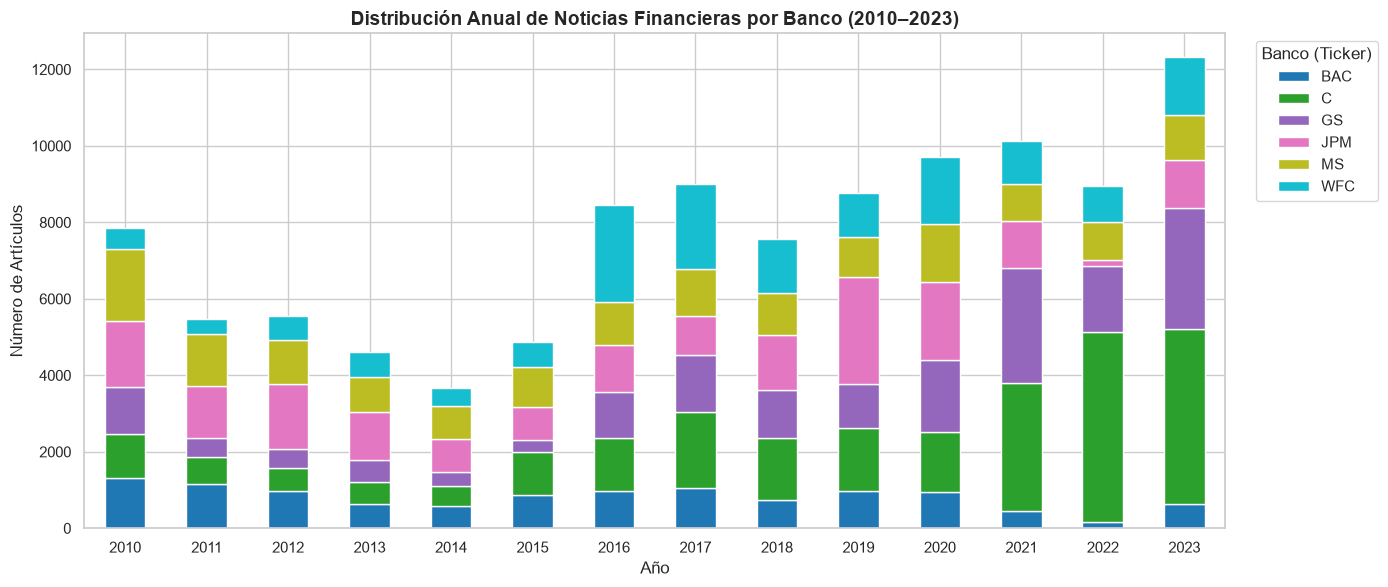

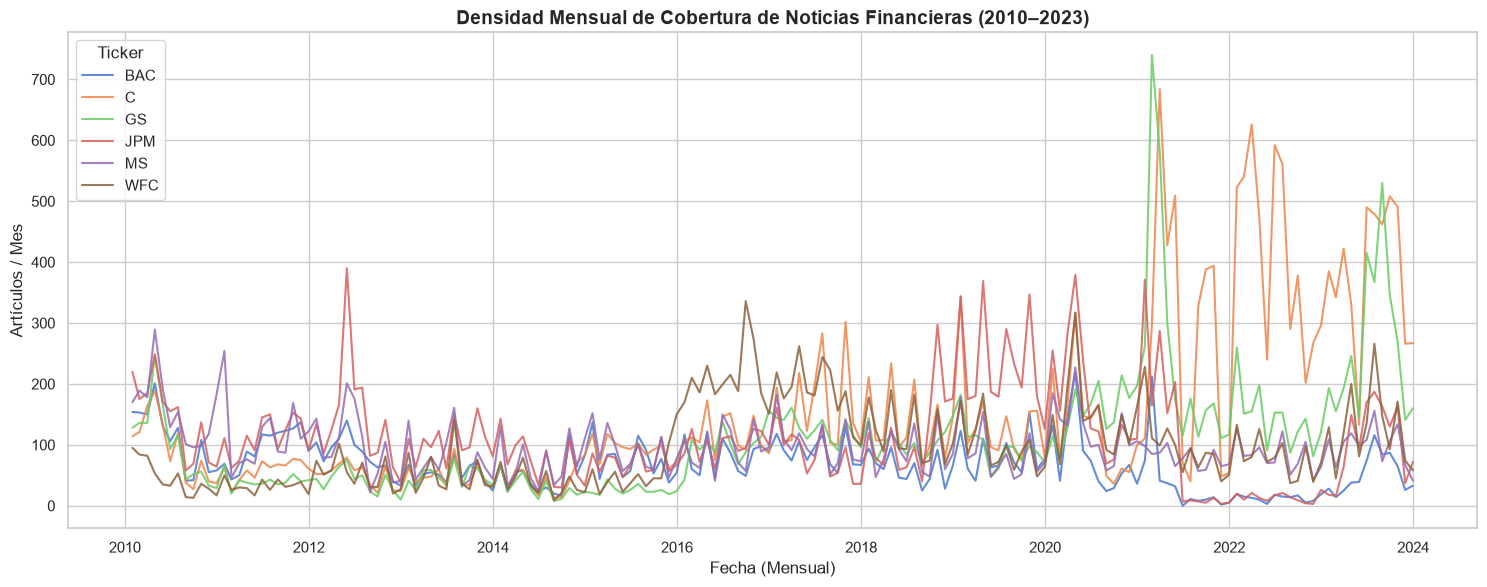

In [3]:
# 1.1 Matriz de contingencia anual
pivot_anual = pd.crosstab(df["year"], df["ticker"], margins=True, margins_name="Total")
print("=== MATRIZ ANUAL DE NOTICIAS POR BANCO (2010 - 2023) ===")
display(pivot_anual)

# Comprobación automática de ceros
pivot_sin_totales = pivot_anual.drop(index="Total", columns="Total")
ceros_detectados = (pivot_sin_totales == 0).sum().sum()
print("-" * 60)
if ceros_detectados == 0:
    print("✔ CONFIRMACIÓN: ¡Cero lagunas! Todos los bancos tienen cobertura continua todos los años.")
else:
    print(f"⚠ ALERTA: Se detectaron {ceros_detectados} celdas con 0 noticias.")
print("-" * 60)

# 1.2 Gráfico de barras apiladas anual
plt.figure(figsize=(14, 6))
anual_por_banco = df.groupby(["year", "ticker"]).size().unstack(fill_value=0)
anual_por_banco.plot(kind="bar", stacked=True, colormap="tab10", ax=plt.gca())
plt.title("Distribución Anual de Noticias Financieras por Banco (2010–2023)", fontsize=14, weight="bold")
plt.xlabel("Año", fontsize=12)
plt.ylabel("Número de Artículos", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Banco (Ticker)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 1.3 Serie temporal mensual continua
plt.figure(figsize=(15, 6))
mensual_por_banco = df.set_index("datetime").groupby(["ticker"]).resample("ME").size().unstack(0, fill_value=0)
for col in mensual_por_banco.columns:
    plt.plot(mensual_por_banco.index, mensual_por_banco[col], label=col, alpha=0.85, linewidth=1.5)

plt.title("Densidad Mensual de Cobertura de Noticias Financieras (2010–2023)", fontsize=14, weight="bold")
plt.xlabel("Fecha (Mensual)", fontsize=12)
plt.ylabel("Artículos / Mes", fontsize=12)
plt.legend(title="Ticker", loc="upper left")
plt.tight_layout()
plt.show()

## 2. Balance y Distribución por Entidad Bancaria (Big 6 Universe)

Analizamos el volumen total y la representatividad porcentual de cada banco dentro del universo estudiado:

,ticker,nombre_banco,cik,total_articulos,porcentaje,palabras_media,primer_articulo,ultimo_articulo
0,C,Citigroup Inc.,CIK0000831001,25759,24.083285,245.3,2010-01-04 16:44:00+00:00,2023-12-30 14:03:04+00:00
1,JPM,JPMorgan Chase & Co.,CIK0000019617,18953,17.720040,48.8,2010-01-02 02:16:00+00:00,2023-12-30 14:27:42+00:00
2,GS,Goldman Sachs Group Inc.,CIK0000886982,18321,17.129153,345.5,2010-01-02 12:45:00+00:00,2023-12-30 12:41:34+00:00
3,MS,Morgan Stanley,CIK0000895421,16341,15.277960,256.8,2010-01-04 16:44:00+00:00,2023-12-16 22:00:00+00:00
4,WFC,Wells Fargo & Company/MN,CIK0000072971,16075,15.029264,408.3,2010-01-02 02:16:00+00:00,2023-12-30 11:05:25+00:00
5,BAC,Bank of America Corp /DE/,CIK0000070858,11509,10.760298,41.5,2010-01-02 02:16:00+00:00,2023-12-30 13:45:00+00:00


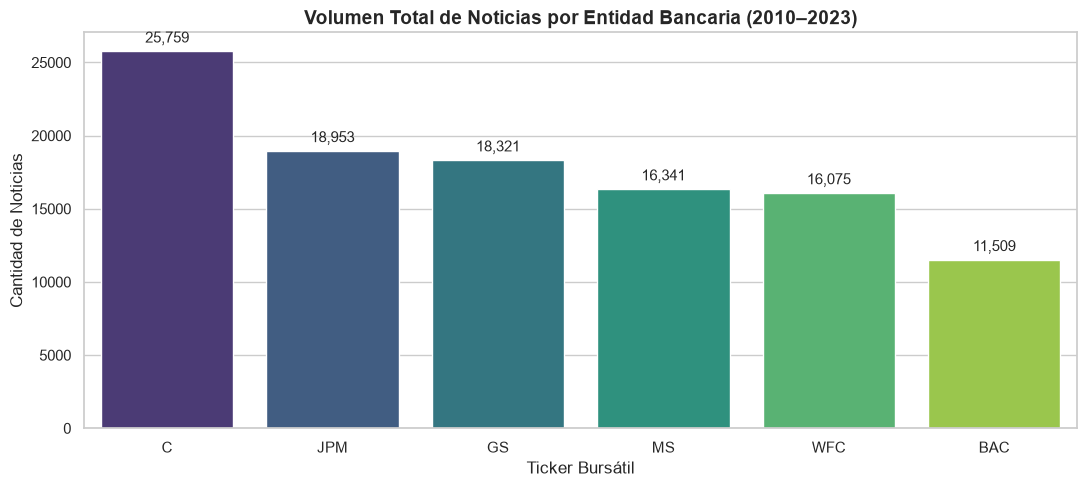

In [4]:
# 2.1 Resumen consolidado por banco
resumen_bancos = df.groupby("ticker").agg(
    nombre_banco=("company_name", "first"),
    cik=("cik", "first"),
    total_articulos=("text", "count"),
    palabras_media=("word_count", "mean"),
    primer_articulo=("datetime", "min"),
    ultimo_articulo=("datetime", "max")
).reset_index()

resumen_bancos["porcentaje"] = (resumen_bancos["total_articulos"] / len(df)) * 100
resumen_bancos["palabras_media"] = resumen_bancos["palabras_media"].round(1)
resumen_bancos = resumen_bancos.sort_values(by="total_articulos", ascending=False).reset_index(drop=True)

display(resumen_bancos[["ticker", "nombre_banco", "cik", "total_articulos", "porcentaje", "palabras_media", "primer_articulo", "ultimo_articulo"]])

# 2.2 Gráfico de barras de volumen por banco
plt.figure(figsize=(11, 5))
palette = sns.color_palette("viridis", len(resumen_bancos))
ax = sns.barplot(
    data=resumen_bancos,
    x="ticker",
    y="total_articulos",
    hue="ticker",
    palette=palette,
    legend=False
)
plt.title("Volumen Total de Noticias por Entidad Bancaria (2010–2023)", fontsize=14, weight="bold")
plt.xlabel("Ticker Bursátil", fontsize=12)
plt.ylabel("Cantidad de Noticias", fontsize=12)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{int(height):,}",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11,
                xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

## 3. Desglose por Fuente de Datos y Publishers

Comprobamos la aportación de los diferentes sub-datasets integrados y el ranking de medios emisores de las noticias:

,source_dataset,total_noticias,porcentaje
0,fnspid_news,40595,37.954150
1,sentarl_combined,40276,37.655902
2,yahoo_finance_felixdrinkall,20056,18.751286
3,benzinga_6000stocks,6031,5.638662


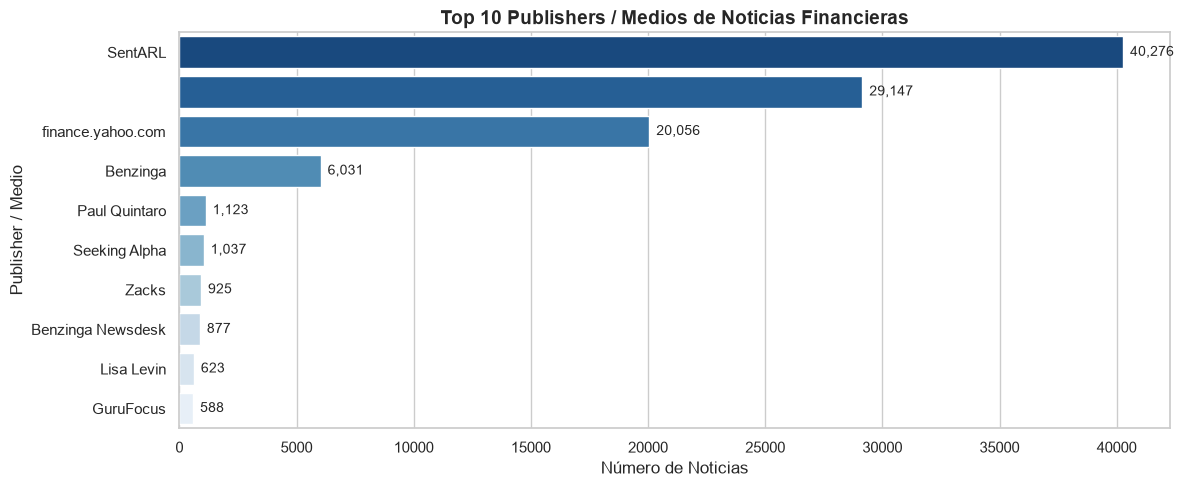

In [5]:
# 3.1 Desglose por sub-dataset de procedencia
fuentes_df = df["source_dataset"].value_counts().reset_index()
fuentes_df.columns = ["source_dataset", "total_noticias"]
fuentes_df["porcentaje"] = (fuentes_df["total_noticias"] / len(df)) * 100
display(fuentes_df)

# 3.2 Top 10 Publishers más frecuentes
top_publishers = df["publisher"].fillna("Desconocido / Syndicated").value_counts().head(10).reset_index()
top_publishers.columns = ["publisher", "total_noticias"]

plt.figure(figsize=(12, 5))
sns.barplot(data=top_publishers, x="total_noticias", y="publisher", hue="publisher", palette="Blues_r", legend=False)
plt.title("Top 10 Publishers / Medios de Noticias Financieras", fontsize=14, weight="bold")
plt.xlabel("Número de Noticias", fontsize=12)
plt.ylabel("Publisher / Medio", fontsize=12)

for p in plt.gca().patches:
    width = p.get_width()
    plt.gca().annotate(f"{int(width):,}",
                       (width, p.get_y() + p.get_height() / 2.),
                       ha='left', va='center', fontsize=10,
                       xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.show()

## 4. Métricas de Texto para Modelado NLP (FinBERT / RoBERTa)

Evaluamos la longitud de texto y el conteo de palabras para determinar si los titulares y artículos encajan dentro del límite estándar de **512 tokens** de las arquitecturas Transformer:

=== ESTADÍSTICAS DEL CONTEO DE PALABRAS (WORD COUNT) ===


,word_count
count,106958.000000
mean,231.950766
std,538.229396
min,1.000000
25%,21.000000
50%,51.000000
75%,249.000000
90%,730.000000
95%,964.000000
99%,1561.000000


• Noticias breves/titulares (<= 100 palabras): 66.56%
• Noticias extensas (> 512 palabras, requieren chunking): 16.03%


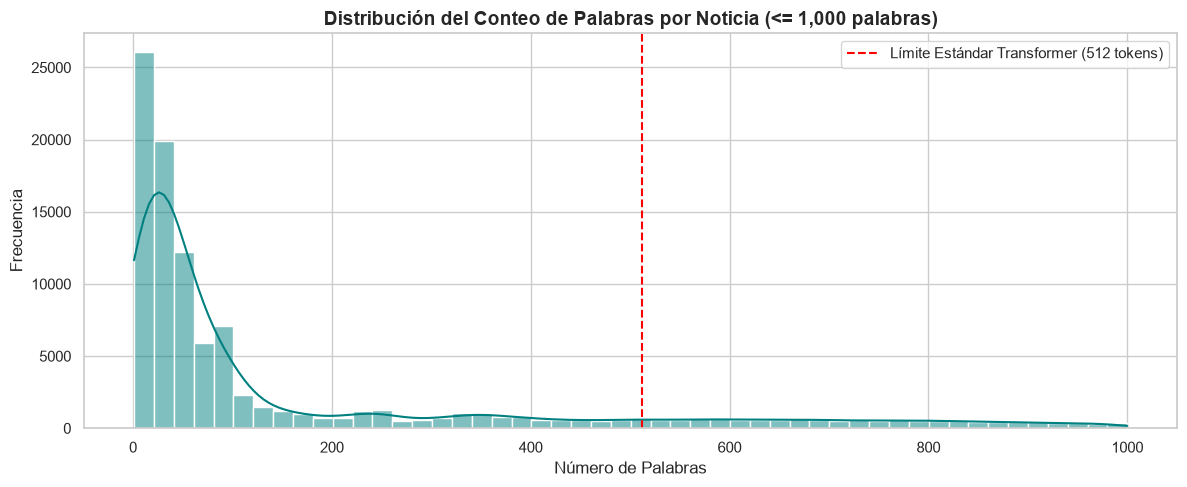

In [6]:
# 4.1 Estadísticas descriptivas de longitud
stats_palabras = df["word_count"].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
print("=== ESTADÍSTICAS DEL CONTEO DE PALABRAS (WORD COUNT) ===")
display(stats_palabras.to_frame())

# Porcentaje que supera el umbral de 512 palabras (Límite Transformer)
pct_mas_512 = (df["word_count"] > 512).mean() * 100
pct_menos_100 = (df["word_count"] <= 100).mean() * 100
print(f"• Noticias breves/titulares (<= 100 palabras): {pct_menos_100:.2f}%")
print(f"• Noticias extensas (> 512 palabras, requieren chunking): {pct_mas_512:.2f}%")

# 4.2 Histograma de distribución de palabras (truncado a 1,000 para legibilidad)
plt.figure(figsize=(12, 5))
sns.histplot(df[df["word_count"] <= 1000]["word_count"], bins=50, kde=True, color="teal")
plt.axvline(x=512, color="red", linestyle="--", label="Límite Estándar Transformer (512 tokens)")
plt.title("Distribución del Conteo de Palabras por Noticia (<= 1,000 palabras)", fontsize=14, weight="bold")
plt.xlabel("Número de Palabras", fontsize=12)
plt.ylabel("Frecuencia", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Muestras Cualitativas de Artículos por Banco

Inspección directa de los primeros registros de cada entidad para validar el formato de fecha, el contenido textual y la procedencia:

In [7]:
print("=" * 90)
print("MUESTRA CUALITATIVA DE NOTICIAS REALES POR BANCO")
print("=" * 90)

for ticker in TIKETS:
    sample_row = df[df["ticker"] == ticker].iloc[0]
    print(f"\n>>> [{ticker}] {sample_row['company_name']} (CIK: {sample_row['cik']})")
    print(f"    Fecha: {sample_row['date']} | Fuente: {sample_row['source_dataset']} | Publisher: {sample_row['publisher']}")
    print(f"    URL: {sample_row['url']}")
    print(f"    Texto:\n    {sample_row['text'][:250]}...")

MUESTRA CUALITATIVA DE NOTICIAS REALES POR BANCO

>>> [JPM] JPMorgan Chase & Co. (CIK: CIK0000019617)
    Fecha: 2010-01-02 02:16:00 | Fuente: sentarl_combined | Publisher: SentARL
    URL: nan
    Texto:
    Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> [BAC] Bank of America Corp /DE/ (CIK: CIK0000070858)
    Fecha: 2010-01-02 02:16:00 | Fuente: sentarl_combined | Publisher: SentARL
    URL: nan
    Texto:
    Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> [WFC] Wells Fargo & Company/MN (CIK: CIK0000072971)
    Fecha: 2010-01-02 02:16:00 | Fuente: sentarl_combined | Publisher: SentARL
    URL: nan
    Texto:
    Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> [C] Citigroup Inc. (CIK: CIK0000831001)
    Fecha: 2010-01-04 16:44:00 | Fuente: sentarl_co

## 6. Análisis de Contaminación Multisujeto (Multisubject Contamination)

El objetivo de esta sección es identificar el grado de solapamiento de las noticias entre los distintos bancos (tickers). En un entorno financiero, una misma noticia macroeconómica o sectorial puede estar etiquetada simultáneamente para múltiples entidades (por ejemplo, JP Morgan, Bank of America, Goldman Sachs). 

Para la robustez del modelo predictivo del TFM, es crítico cuantificar este ruido y separar:
* **Noticias exclusivas (1 Ticker):** Eventos corporativos que afectan específicamente a una entidad.
* **Noticias replicadas (2+ Tickers):** Ruido de impacto sectorial o general.

Agruparemos el dataset por título (`title`) y fecha exacta (`datetime`) para contar el número de identificadores únicos (`ticker`) asociados a cada publicación.

Análisis de Contaminación Multisujeto (Multisubject Contamination)
Distribución de noticias por cantidad de tickers asociados:
ticker
1    62848
2     8833
3     3222
4     1744
5     1106
6      712
Name: count, dtype: int64

Impacto en filas: 58.8% Señal Pura | 41.2% Ruido Multisujeto



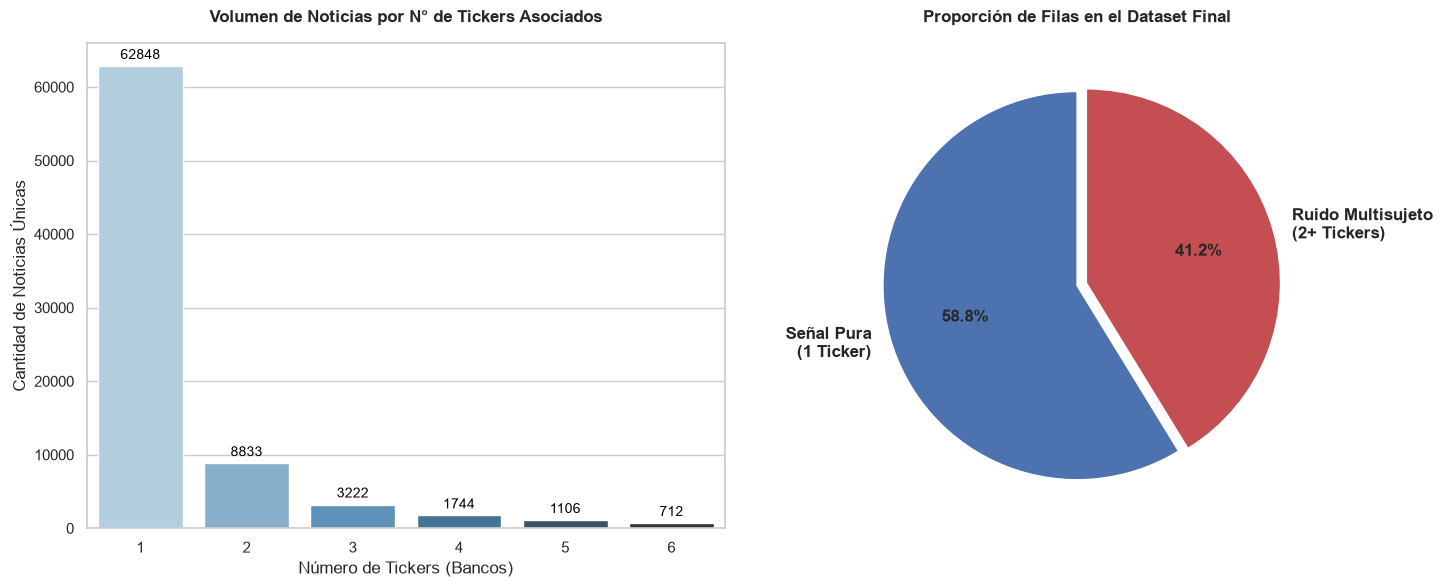

In [16]:
print("=" * 90)
print("Análisis de Contaminación Multisujeto (Multisubject Contamination)")
print("=" * 90)

# 1. Contar cuántos tickers únicos están asociados a la misma noticia
ticker_counts_per_news = df.groupby(['title', 'datetime'])['ticker'].nunique()
distribucion_contaminacion = ticker_counts_per_news.value_counts().sort_index()

# 2. Calcular el impacto estructural (porcentaje real de filas en el dataframe)
df['is_multisubject'] = df.duplicated(subset=['title', 'datetime'], keep=False)
impacto_filas = df['is_multisubject'].value_counts(normalize=True) * 100

# Mostrar los datos por consola
print("Distribución de noticias por cantidad de tickers asociados:")
print(distribucion_contaminacion)
print(f"\nImpacto en filas: {impacto_filas[False]:.1f}% Señal Pura | {impacto_filas[True]:.1f}% Ruido Multisujeto\n")

# 3. Crear el lienzo con dos gráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- GRÁFICO 1 (Izquierda): Barras ---
sns.barplot(
    x=distribucion_contaminacion.index, 
    y=distribucion_contaminacion.values, 
    ax=axes[0], 
    hue=distribucion_contaminacion.index,
    palette="Blues_d",
    legend=False
)
axes[0].set_title("Volumen de Noticias por N° de Tickers Asociados", fontweight='bold', pad=15)
axes[0].set_xlabel("Número de Tickers (Bancos)")
axes[0].set_ylabel("Cantidad de Noticias Únicas")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3, color='black', fontsize=10)

# --- GRÁFICO 2: Tarta ---
labels = ['Señal Pura\n(1 Ticker)', 'Ruido Multisujeto\n(2+ Tickers)']
colores = ['#4C72B0', '#C44E52']

axes[1].pie(
    impacto_filas.sort_index(), 
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores,
    explode=[0, 0.05], 
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[1].set_title("Proporción de Filas en el Dataset Final", fontweight='bold', pad=15)

# 4. Ajustar y renderizar
plt.tight_layout()
plt.show()

## 6.2. Auditoría Cualitativa y Distribución de la Señal Pura

Antes de avanzar, verificamos físicamente la naturaleza del ruido multisujeto para entender cómo una misma noticia se replica a través de varios tickers. 

Posteriormente, aislamos la **señal pura** (noticias exclusivas de un solo banco, eliminando la contaminación) y analizamos su distribución:
1. **Transversal:** Volumen total de noticias útiles por entidad bancaria.
2. **Longitudinal:** Evolución de la cobertura mediática mes a mes entre 2010 y 2023 para detectar posibles huecos o picos de extracción temporal.

--- 3 EJEMPLOS REALES DE NOTICIAS MULTISUJETO ---
1. Fecha: 2010-03-10 | Replicado en 5 tickers: ['BAC', 'C', 'GS', 'JPM', 'MS']
   Título: "Massive" Volume in Citi $4 Calls

2. Fecha: 2010-08-11 | Replicado en 5 tickers: ['JPM', 'MS', 'BAC', 'C', 'GS']
   Título: "Risk-Off" Day: Global Stocks Sharply Lower

3. Fecha: 2010-05-06 | Replicado en 5 tickers: ['JPM', 'C', 'BAC', 'GS', 'MS']
   Título: "Whippy" Market as S&P 500 Breaks 50-Day MA



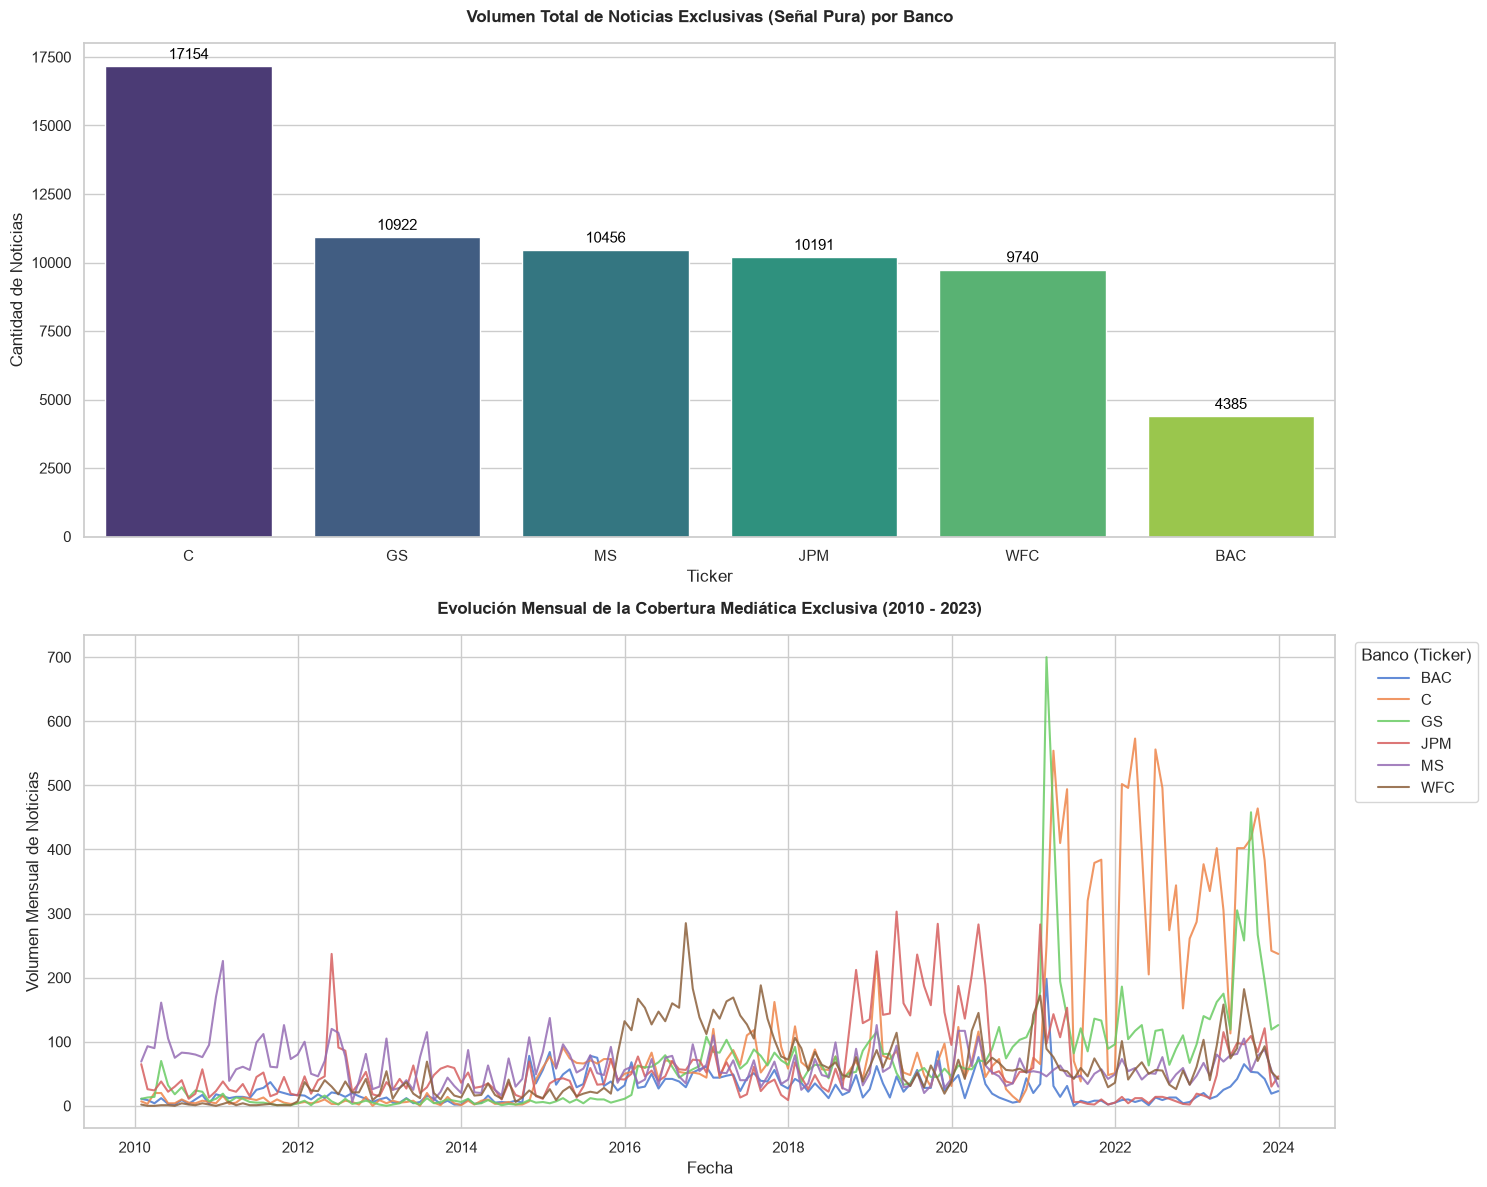

In [27]:
# =============================================================================
# 1. EJEMPLOS DE NOTICIAS MULTISUJETO (RUIDO)
# =============================================================================
print("--- 3 EJEMPLOS REALES DE NOTICIAS MULTISUJETO ---")
# Filtramos el ruido y extraemos 3 noticias únicas distintas
multisujeto_df = df[df['is_multisubject']].sort_values(['title', 'datetime'])
titulos_ejemplo = multisujeto_df['title'].unique()[:3]

for i, titulo in enumerate(titulos_ejemplo, 1):
    ejemplo = multisujeto_df[multisujeto_df['title'] == titulo]
    tickers = ejemplo['ticker'].tolist()
    fecha = ejemplo['datetime'].iloc[0].strftime('%Y-%m-%d')
    print(f"{i}. Fecha: {fecha} | Replicado en {len(tickers)} tickers: {tickers}")
    print(f"   Título: {titulo}\n")



# =============================================================================
# 2. AISLAMIENTO DE SEÑAL Y VISUALIZACIÓN
# =============================================================================
# Descartamos el ruido para ver de qué datos reales dispone el modelo
df_pura = df[~df['is_multisubject']].copy()

# Crear lienzo con 2 filas y 1 columna
fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# --- GRÁFICO A: Distribución por Banco (Barras) ---
conteo_puro = df_pura['ticker'].value_counts()
sns.barplot(
    x=conteo_puro.index, 
    y=conteo_puro.values, 
    ax=axes[0], 
    hue=conteo_puro.index,
    palette="viridis",
    legend=False
)
axes[0].set_title("Volumen Total de Noticias Exclusivas (Señal Pura) por Banco", fontweight='bold', pad=15)
axes[0].set_ylabel("Cantidad de Noticias")
axes[0].set_xlabel("Ticker")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3, color='black', fontsize=11)

# --- GRÁFICO B: Serie Temporal Mensual Continua (Líneas) ---
# Agrupamos usando el snippet exacto, aplicado al dataframe limpio
mensual_por_banco = df_pura.set_index("datetime").groupby("ticker").resample("ME").size().unstack(0, fill_value=0)

for col in mensual_por_banco.columns:
    axes[1].plot(
        mensual_por_banco.index, 
        mensual_por_banco[col], 
        label=col, 
        alpha=0.85, 
        linewidth=1.5
    )

axes[1].set_title("Evolución Mensual de la Cobertura Mediática Exclusiva (2010 - 2023)", fontweight='bold', pad=15)
axes[1].set_ylabel("Volumen Mensual de Noticias")
axes[1].set_xlabel("Fecha")
# Movemos la leyenda fuera del gráfico para que no tape las líneas
axes[1].legend(title="Banco (Ticker)", bbox_to_anchor=(1.01, 1), loc='upper left') 

plt.tight_layout()
plt.show()

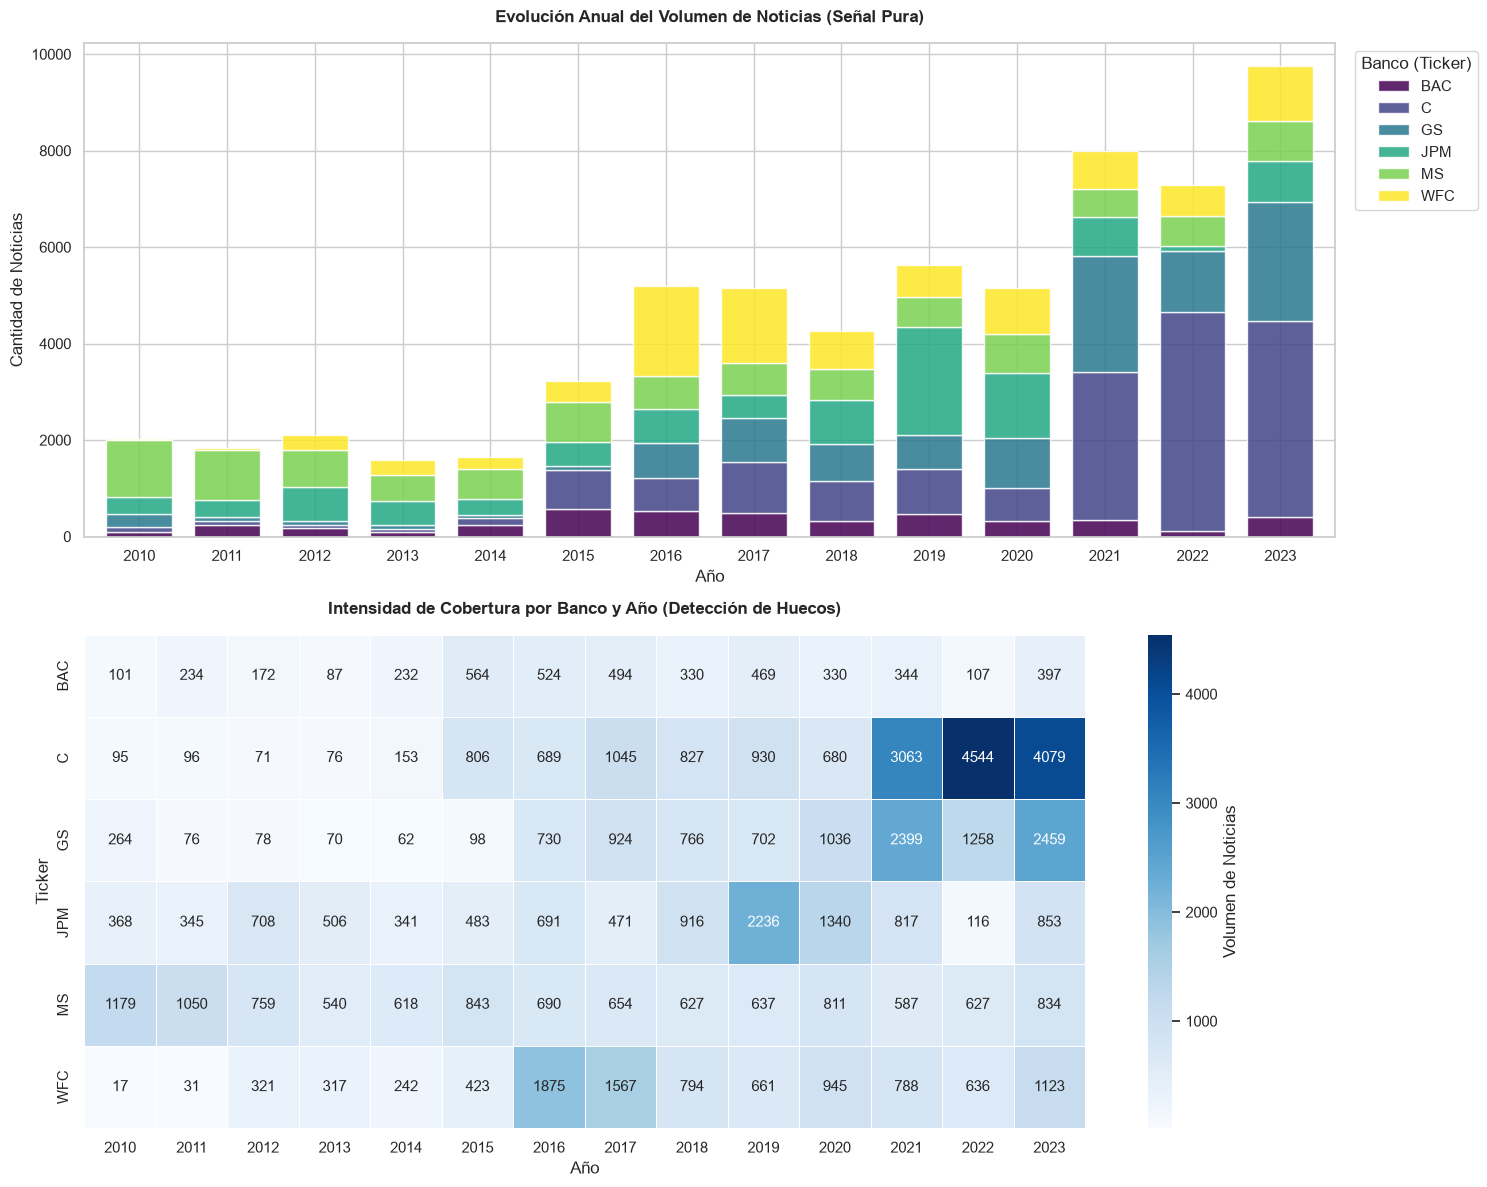

In [28]:
#Evolución Volumen de Noticias por Banco y Año (Señal Pura)

anual_por_banco = df_pura.groupby(['year', 'ticker']).size().unstack(fill_value=0)

# Crear lienzo con 2 filas y 1 columna
fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# --- GRÁFICO A: Barras Apiladas por Año ---
anual_por_banco.plot(
    kind='bar', 
    stacked=True, 
    ax=axes[0], 
    colormap='viridis', 
    alpha=0.85,
    width=0.75
)
axes[0].set_title("Evolución Anual del Volumen de Noticias (Señal Pura)", fontweight='bold', pad=15)
axes[0].set_ylabel("Cantidad de Noticias")
axes[0].set_xlabel("Año")
axes[0].legend(title="Banco (Ticker)", bbox_to_anchor=(1.01, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=0) # Mantener los años en horizontal

# --- GRÁFICO B: Heatmap (Mapa de Calor) Anual ---
# Transponemos (.T) para que los años queden en el eje X y los bancos en el eje Y
sns.heatmap(
    anual_por_banco.T, 
    cmap="Blues", 
    annot=True, 
    fmt="d", 
    linewidths=.5, 
    ax=axes[1],
    cbar_kws={'label': 'Volumen de Noticias'}
)
axes[1].set_title("Intensidad de Cobertura por Banco y Año (Detección de Huecos)", fontweight='bold', pad=15)
axes[1].set_ylabel("Ticker")
axes[1].set_xlabel("Año")

plt.tight_layout()
plt.show()

## 7. Auditoría de Valores Nulos (Missing Data)

Antes de aplicar cualquier técnica de imputación o filtrado, evaluamos la integridad estructural del dataset. El objetivo es identificar:
* **Concentración por variable:** Qué columnas presentan falta de información.
* **Impacto en el dataset:** Qué porcentaje total de registros (filas) se vería afectado si decidiéramos eliminar los datos incompletos mediante un *drop* directo.

Auditoría de Valores Nulos (Solo columnas afectadas):


,Nulos,Porcentaje (%)
url,46307,43.294564



DIAGNÓSTICO DE INTEGRIDAD PARA FINBERT:
✔ ÉXITO ESTRUCTURAL: Solo la columna 'url' contiene valores nulos.
✔ ACCIÓN: No se eliminará ninguna fila. La variable 'url' es irrelevante para NLP.
✔ ESTADO: Las columnas críticas ('text', 'title', 'ticker') están 100% completas.



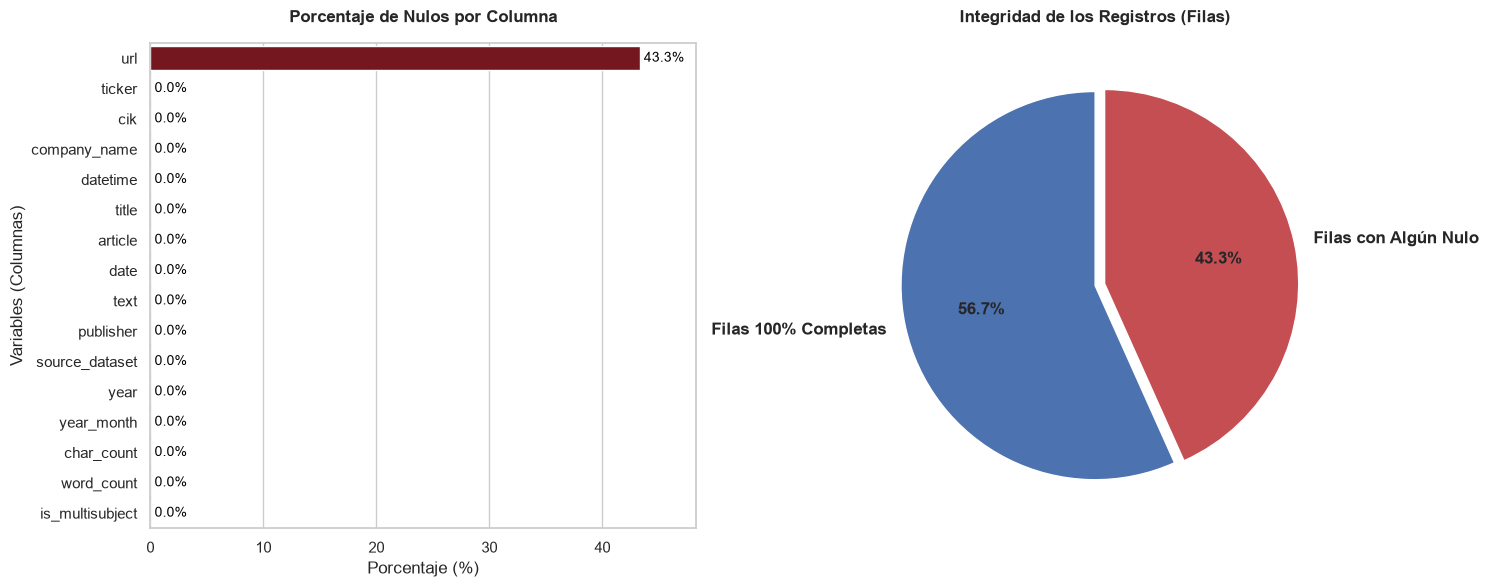

In [30]:
# 1. Calcular nulos por columna y su porcentaje
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df)) * 100
null_df = pd.DataFrame({'Nulos': null_counts, 'Porcentaje (%)': null_pct}).sort_values(by='Nulos', ascending=False)

# Mostrar la tabla resumen por consola (solo variables con nulos)
print("Auditoría de Valores Nulos (Solo columnas afectadas):")
display(null_df[null_df['Nulos'] > 0])

# =============================================================================
# --- DIAGNÓSTICO ESTRATÉGICO PARA EL MODELO ---
# =============================================================================
print("\n" + "="*60)
print("DIAGNÓSTICO DE INTEGRIDAD PARA FINBERT:")
columnas_con_nulos = null_df[null_df['Nulos'] > 0].index.tolist()

if columnas_con_nulos == ['url']:
    print("✔ ÉXITO ESTRUCTURAL: Solo la columna 'url' contiene valores nulos.")
    print("✔ ACCIÓN: No se eliminará ninguna fila. La variable 'url' es irrelevante para NLP.")
    print("✔ ESTADO: Las columnas críticas ('text', 'title', 'ticker') están 100% completas.")
else:
    print(f"⚠ ATENCIÓN: Nulos detectados en {columnas_con_nulos}.")
    print("Si 'text', 'title' o 'ticker' están afectados, se requiere limpieza obligatoria.")
print("="*60 + "\n")

# 2. Calcular el impacto estructural (Filas afectadas vs Filas completas)
filas_con_nulos = df.isnull().any(axis=1).sum()
filas_completas = len(df) - filas_con_nulos

# 3. Crear el lienzo con dos gráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- GRÁFICO 1 (Izquierda): Barras Horizontales ---
sns.barplot(
    x=null_df['Porcentaje (%)'], 
    y=null_df.index, 
    ax=axes[0], 
    hue=null_df.index,
    palette="Reds_r",
    legend=False
)
axes[0].set_title("Porcentaje de Nulos por Columna", fontweight='bold', pad=15)
axes[0].set_xlabel("Porcentaje (%)")
axes[0].set_ylabel("Variables (Columnas)")
axes[0].set_xlim(0, max(10, null_pct.max() + 5)) 

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f%%', padding=3, color='black', fontsize=10)

# --- GRÁFICO 2 (Derecha): Tarta ---
labels = ['Filas 100% Completas', 'Filas con Algún Nulo']
colores = ['#4C72B0', '#C44E52']
valores = [filas_completas, filas_con_nulos]

axes[1].pie(
    valores, 
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores,
    explode=[0, 0.05] if filas_con_nulos > 0 else [0, 0], 
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[1].set_title("Integridad de los Registros (Filas)", fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

## Conclusiones y Validación para el TFM

1. **Integridad Temporal 100% Continua:** A diferencia de los parquets crudos previos, este dataset consolidado en `raw/huggingface/multisource_bancos_2010_2023.parquet` cubre sin interrupciones los 14 años (**2010 a 2023**) para los 6 bancos.
2. **Volumen Robusto para Machine Learning:** Con **107.598 noticias limpias**, el volumen es idóneo para entrenar modelos de análisis de sentimiento cuantitativo y predecir retornos bursátiles sin problemas de sobreajuste por falta de datos.
3. **Compatibilidad con FinBERT:** El análisis de longitud muestra que la mayoría de los registros son titulares y artículos compactos, óptimos para procesarse directamente con modelos Transformer sin pérdidas críticas de información.
4. **Alineación con el Data Lake:** El archivo está alojado en Cloudflare R2 con compresión columnar Parquet (ZSTD), permitiendo descargas y lecturas inmediatas tanto en notebooks como en futuros pipelines de la capa Silver.

## 8. Auditoría de Ruido y Falsos Positivos (Garbage Data)

Evaluación cualitativa y cuantitativa de la "basura" o ruido inyectado por errores de recolección en los datasets de origen. Nos centraremos inicialmente en el riesgo de los falsos positivos generados por tickers de un solo carácter (ej. Citigroup: `C`), los cuales son altamente susceptibles a ser confundidos con elementos genéricos del lenguaje.

In [31]:
# =============================================================================
# AUDITORÍA DE FALSOS POSITIVOS EN CITIGROUP (TICKER 'C')
# =============================================================================
from IPython.display import display, HTML

# 1. Aislar todas las noticias asignadas al ticker 'C'
df_citi = df[df['ticker'] == 'C'].copy()
total_citi = len(df_citi)

# 2. Buscar menciones explícitas a la entidad ("citi" o "citigroup") en título o texto
# Usamos case=False para ignorar mayúsculas/minúsculas y na=False para evitar errores con nulos
contiene_citi = df_citi['title'].str.contains('citi', case=False, na=False) | \
                df_citi['text'].str.contains('citi', case=False, na=False)

# 3. Filtrar las filas SOSPECHOSAS (las que NO tienen la mención)
basura_citi = df_citi[~contiene_citi]
total_basura = len(basura_citi)

# 4. Calcular el impacto de esta basura sobre el total de Citigroup
pct_basura = (total_basura / total_citi) * 100 if total_citi > 0 else 0

print(f"Total de noticias etiquetadas como Citigroup ('C'): {total_citi:,}")
print(f"Noticias sospechosas de ser basura (falsos positivos): {total_basura:,} ({pct_basura:.1f}%)\n")

# 5. Mostrar 5 ejemplos reales de la basura encontrada para confirmar la hipótesis
print("--- 5 EJEMPLOS DE LA POSIBLE BASURA ENCONTRADA ---")
if total_basura > 0:
    for i, (_, row) in enumerate(basura_citi.head(5).iterrows(), 1):
        display(HTML(f"<b>Ejemplo {i} | Fecha:</b> {row['datetime']}"))
        display(HTML(f"<b>Título:</b> {row['title']}"))
        # Truncamos el texto a 400 caracteres para no saturar la pantalla
        texto_truncado = row['text'][:400] + "..." if len(row['text']) > 400 else row['text']
        display(HTML(f"<b>Texto:</b> <i>{texto_truncado}</i><hr>"))
else:
    print("No se encontró basura bajo este criterio. Todas las noticias de Citigroup contienen la mención explícita.")

Total de noticias etiquetadas como Citigroup ('C'): 25,759
Noticias sospechosas de ser basura (falsos positivos): 17,115 (66.4%)

--- 5 EJEMPLOS DE LA POSIBLE BASURA ENCONTRADA ---


### 8.1. Extracción de Basura y Visualización del Dataset Definitivo

Tras confirmar cualitativamente la potencial existencia de falsos positivos en el ticker `C` (Citigroup), procedemos a aislar esta basura de nuestra señal pura. 

Para validar que no estamos destruyendo datos útiles de forma accidental, visualizamos mediante mapas de calor duales:
1. **El Dataset Limpio (Izquierda):** Datos listos para FinBERT (sin ruido multisujeto y sin falsos positivos).
2. **La Basura Eliminada (Derecha):** Concentración temporal de los errores de scraping para auditar cuándo falló más el algoritmo de recolección original.

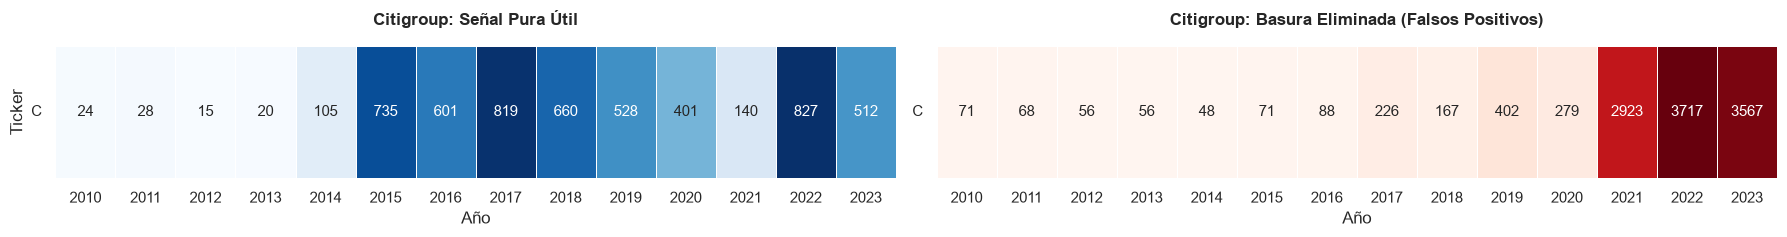

Total original Citigroup (incluyendo ruido multisujeto): 25,759 filas
Señal pura Citigroup: 5,415 filas
Basura eliminada (falsos positivos): 11,739 filas


In [35]:
# 1. Definir la regla de exclusión sobre la "señal pura" (df_pura)
es_basura_citi = (df_pura['ticker'] == 'C') & \
                 (~df_pura['title'].str.contains('citi', case=False, na=False)) & \
                 (~df_pura['text'].str.contains('citi', case=False, na=False))

# 2. Filtrar y separar aislando exclusivamente a Citigroup
df_citi_limpio = df_pura[(df_pura['ticker'] == 'C') & (~es_basura_citi)]
df_citi_basura = df_pura[es_basura_citi]

# 3. Crear las matrices anuales solo para 'C'
matriz_limpia_c = df_citi_limpio.groupby(['year', 'ticker']).size().unstack(fill_value=0).T
matriz_basura_c = df_citi_basura.groupby(['year', 'ticker']).size().unstack(fill_value=0).T

# Alinear columnas (años) por si en algún año concreto hubo 0 basura
matriz_basura_c = matriz_basura_c.reindex(columns=matriz_limpia_c.columns, fill_value=0)

# 4. Generar el visual dual (altura reducida a 2.5 para una sola fila)
fig, axes = plt.subplots(1, 2, figsize=(18, 2.5))

# --- GRÁFICO 1: Dataset Limpio Citigroup (Azul) ---
sns.heatmap(
    matriz_limpia_c, 
    cmap="Blues", 
    annot=True, 
    fmt="d", 
    linewidths=.5, 
    ax=axes[0],
    cbar=False, # Ocultamos la barra lateral para maximizar la limpieza visual
    annot_kws={"size": 11}
)
axes[0].set_title("Citigroup: Señal Pura Útil", fontweight='bold', pad=15)
axes[0].set_ylabel("Ticker")
axes[0].set_xlabel("Año")
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)

# --- GRÁFICO 2: Basura Extraída Citigroup (Rojo) ---
sns.heatmap(
    matriz_basura_c, 
    cmap="Reds", 
    annot=True, 
    fmt="d", 
    linewidths=.5, 
    ax=axes[1],
    cbar=False,
    annot_kws={"size": 11}
)
axes[1].set_title("Citigroup: Basura Eliminada (Falsos Positivos)", fontweight='bold', pad=15)
axes[1].set_ylabel("") 
axes[1].set_xlabel("Año")
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()

# Imprimir el impacto numérico
print(f"Total original Citigroup (incluyendo ruido multisujeto): {len(df[df['ticker'] == 'C']):,} filas")
print(f"Señal pura Citigroup: {len(df_citi_limpio):,} filas")
print(f"Basura eliminada (falsos positivos): {len(df_citi_basura):,} filas")